In [7]:

# ============================================================
# Random Forest - Complete-case Analysis
# Football Match Outcome Classification
#
# Target:
# FTR = H (Home Win), D (Draw), A (Away Win)
#
# Predictors:
# Full-time match statistics (excluding goals and betting odds)
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 1. FILE PATHS

from pathlib import Path

# Find the project root
current = Path.cwd().resolve()

if (current / "processed-data").is_dir():
    ROOT = current
elif (current.parent / "processed-data").is_dir():
    ROOT = current.parent
elif (current.parent.parent / "processed-data").is_dir():
    ROOT = current.parent.parent
else:
    raise FileNotFoundError("Cannot find the processed-data folder")

OUTPUT = ROOT / "BingquanW" / "04_RandomForest"
OUTPUT.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = (
    ROOT / "processed-data" / "football_train_data.csv"
)

TEST_PATH = (
    ROOT / "processed-data" / "football_test_data.csv"
)


# ============================================================
# 2. LOAD DATA
# ============================================================

print("\n===== LOADING DATA =====")

train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)

FEATURES = [
    "HS", "AS",
    "HST", "AST",
    "HF", "AF",
    "HC", "AC",
    "HY", "AY",
    "HR", "AR"
]

TARGET = "FTR"
CLASSES = ["H", "D", "A"]

# Check required columns
required_columns = FEATURES + [TARGET]

for name, dataset in [
    ("Training", train),
    ("Testing", test)
]:
    missing_columns = [
        col for col in required_columns
        if col not in dataset.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{name} dataset is missing columns: "
            f"{missing_columns}"
        )

# Keep valid target labels
train = train[
    train[TARGET].isin(CLASSES)
].copy()

test = test[
    test[TARGET].isin(CLASSES)
].copy()

X_train = train[FEATURES].apply(
    pd.to_numeric,
    errors="coerce"
)

X_test = test[FEATURES].apply(
    pd.to_numeric,
    errors="coerce"
)

y_train = train[TARGET].copy()
y_test = test[TARGET].copy()

print("Original training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", len(FEATURES))


# ============================================================
# 3. COMPLETE-CASE ANALYSIS
# ============================================================

print("\n===== COMPLETE-CASE ANALYSIS =====")

print("\nMissing values in training features:")
print(X_train.isna().sum())

# Identify training rows with missing predictors
missing_mask = X_train.isna().any(axis=1)

removed_rows = int(missing_mask.sum())

print("\nRows with missing predictors:", removed_rows)

print(
    "Indices of removed rows:",
    X_train.index[missing_mask].tolist()
)

# Remove incomplete rows from training data only
complete_mask = ~missing_mask

X_train_clean = X_train.loc[
    complete_mask
].copy()

y_train_clean = y_train.loc[
    complete_mask
].copy()

print(
    "Training rows after cleaning:",
    len(X_train_clean)
)

# Do not silently remove test observations
test_missing = X_test.isna().sum()

if test_missing.sum() > 0:
    raise ValueError(
        "The test dataset contains missing predictors. "
        "Review test preprocessing before evaluation.\n"
        + str(test_missing[test_missing > 0])
    )

# Save a summary of cleaning
cleaning_summary = pd.DataFrame({
    "Measure": [
        "Original training rows",
        "Removed training rows",
        "Remaining training rows",
        "Testing rows"
    ],
    "Value": [
        len(X_train),
        removed_rows,
        len(X_train_clean),
        len(X_test)
    ]
})

cleaning_summary.to_csv(
    OUTPUT / "rf_complete_case_cleaning.csv",
    index=False
)


# ============================================================
# 4. TRAIN RANDOM FOREST
# ============================================================

print("\n===== TRAINING RANDOM FOREST =====")

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train_clean,
    y_train_clean
)

print("Random Forest training completed.")


# ============================================================
# 5. MAKE PREDICTIONS
# ============================================================

print("\n===== MAKING PREDICTIONS =====")

y_pred = model.predict(X_test)

probabilities = model.predict_proba(X_test)

probability_df = pd.DataFrame(
    probabilities,
    columns=[
        f"Probability_{label}"
        for label in model.classes_
    ],
    index=X_test.index
)

predictions_df = pd.DataFrame({
    "Actual_FTR": y_test,
    "Predicted_FTR": y_pred
}, index=X_test.index)

for label in CLASSES:
    predictions_df[
        f"Probability_{label}"
    ] = probability_df[
        f"Probability_{label}"
    ]

predictions_df.to_csv(
    OUTPUT / "rf_complete_case_predictions.csv",
    index=False
)

print("Predictions saved.")


# ============================================================
# 6. EVALUATE MODEL
# ============================================================

print("\n===== MODEL EVALUATION =====")

accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    labels=CLASSES,
    average="macro",
    zero_division=0
)

draw_recall = recall_score(
    y_test,
    y_pred,
    labels=["D"],
    average="macro",
    zero_division=0
)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Draw Recall: {draw_recall:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=CLASSES,
        zero_division=0
    )
)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro_F1",
        "Draw_Recall"
    ],
    "Value": [
        accuracy,
        macro_f1,
        draw_recall
    ]
})

metrics_df.to_csv(
    OUTPUT / "rf_complete_case_metrics.csv",
    index=False
)


# ============================================================
# 7. CONFUSION MATRIX
# ============================================================

print("\n===== CONFUSION MATRIX =====")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=CLASSES
)

print(
    pd.DataFrame(
        cm,
        index=CLASSES,
        columns=CLASSES
    )
)

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Home Win",
        "Draw",
        "Away Win"
    ]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Random Forest - Complete-case Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    OUTPUT / "rf_complete_case_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)


# ============================================================
# 8. FEATURE IMPORTANCE
# ============================================================

print("\n===== FEATURE IMPORTANCE =====")

importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print(importance_df.to_string(index=False))

importance_df.to_csv(
    OUTPUT / "rf_complete_case_feature_importance.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 6))

plot_data = importance_df.sort_values(
    "Importance",
    ascending=True
)

ax.barh(
    plot_data["Feature"],
    plot_data["Importance"]
)

ax.set_xlabel("Feature Importance")

ax.set_title(
    "Random Forest - Complete-case Feature Importance"
)

plt.tight_layout()

plt.savefig(
    OUTPUT / "rf_complete_case_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n======================================")
print("FINAL RANDOM FOREST RESULTS")
print("======================================")

print("Missing-data method: Complete-case")
print("Removed training rows:", removed_rows)
print("Remaining training rows:", len(X_train_clean))

print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro F1: {macro_f1 * 100:.2f}%")
print(f"Draw Recall: {draw_recall * 100:.2f}%")

print("\nAnalysis completed successfully!")
print("Results saved in:", OUTPUT)



===== LOADING DATA =====
Original training rows: 37824
Testing rows: 8740
Number of features: 12

===== COMPLETE-CASE ANALYSIS =====

Missing values in training features:
HS     1
AS     1
HST    1
AST    1
HF     3
AF     3
HC     1
AC     1
HY     1
AY     1
HR     1
AR     1
dtype: int64

Rows with missing predictors: 3
Indices of removed rows: [8807, 32939, 32948]
Training rows after cleaning: 37821

===== TRAINING RANDOM FOREST =====
Random Forest training completed.

===== MAKING PREDICTIONS =====
Predictions saved.

===== MODEL EVALUATION =====

Accuracy: 0.5721
Macro F1: 0.4576
Draw Recall: 0.0621

Classification Report:
              precision    recall  f1-score   support

           H       0.60      0.83      0.69      3976
           D       0.40      0.06      0.11      2159
           A       0.55      0.60      0.57      2605

    accuracy                           0.57      8740
   macro avg       0.51      0.50      0.46      8740
weighted avg       0.53      0.57   

In [8]:
# ==========================================
# Multiclass ROC-AUC Evaluation
# ==========================================

from sklearn.metrics import roc_auc_score

# Predict probabilities for H, D and A
y_proba = model.predict_proba(X_test)

# Calculate multiclass ROC-AUC (One-vs-Rest)
auc = roc_auc_score(
    y_test,
    y_proba,
    labels=model.classes_,
    multi_class="ovr",
    average="macro"
)

print("=" * 40)
print("RANDOM FOREST - AUC RESULTS")
print("=" * 40)
print(f"Multiclass ROC-AUC: {auc:.4f}")

RANDOM FOREST - AUC RESULTS
Multiclass ROC-AUC: 0.7134



### Multiclass ROC-AUC

**Why we use this metric**

We use multiclass ROC-AUC to evaluate how well the model distinguishes between match outcomes based on predicted probabilities.

The metric is calculated using a one-vs-rest approach with macro averaging, allowing the three outcomes to contribute equally.

**What our result means**

The model achieved a multiclass ROC-AUC of 0.7134.

This indicates a moderate ability to distinguish between match outcomes, with better discrimination than a random-ranking benchmark of 0.5.

However, ROC-AUC does not directly show how many matches were classified correctly. Therefore, it provides different information from accuracy.


In [9]:
# Multiclass Log Loss Evaluation

from sklearn.metrics import log_loss

y_proba = model.predict_proba(X_test)

loss = log_loss(
    y_test,
    y_proba,
    labels=model.classes_
)

print("=" * 40)
print("MULTICLASS LOG LOSS RESULTS")
print("=" * 40)
print(f"Multiclass Log Loss: {loss:.4f}")

MULTICLASS LOG LOSS RESULTS
Multiclass Log Loss: 0.9240



### Multiclass Log Loss

**Why we use this metric**

We use Log Loss to evaluate the probabilities assigned by the Random Forest model to home wins, draws and away wins.

Unlike accuracy, Log Loss considers how confident the model is in its predictions. Confident incorrect predictions receive larger penalties.

**What our result means**

The model achieved a Log Loss of 0.9240.

A lower Log Loss indicates better probabilistic predictions. This result provides a benchmark for comparison with the Random Forest model that includes betting odds.

Log Loss cannot be interpreted as a percentage of correctly predicted matches, and its value alone does not establish whether the predicted probabilities are well calibrated.


In [17]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss
)
from IPython.display import display as show_table

# Original Random Forest without Odds
y_pred_baseline = model.predict(X_test)
y_proba_baseline = model.predict_proba(X_test)

baseline_metrics = {
    "Accuracy (%)": accuracy_score(
        y_test, y_pred_baseline
    ) * 100,

    "Macro Precision (%)": precision_score(
        y_test, y_pred_baseline,
        average="macro", zero_division=0
    ) * 100,

    "Macro Recall (%)": recall_score(
        y_test, y_pred_baseline,
        average="macro", zero_division=0
    ) * 100,

    "Macro F1 (%)": f1_score(
        y_test, y_pred_baseline,
        average="macro", zero_division=0
    ) * 100,

    "Multiclass ROC-AUC": roc_auc_score(
        y_test,
        y_proba_baseline,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    ),

    "Multiclass Log Loss": log_loss(
        y_test,
        y_proba_baseline,
        labels=model.classes_
    )
}

baseline_results = pd.DataFrame({
    "Metric": list(baseline_metrics.keys()),
    "Value": list(baseline_metrics.values())
})

show_table(baseline_results.round(4))


,Metric,Value
0,Accuracy (%),57.2082
1,Macro Precision (%),51.4448
2,Macro Recall (%),49.7424
3,Macro F1 (%),45.7643
4,Multiclass ROC-AUC,0.7134
5,Multiclass Log Loss,0.9240



### Accuracy

**Why we use this metric**

Accuracy measures the proportion of correctly classified matches. We use it to evaluate the overall classification performance of the Random Forest model on Premier League matches.

**What our result means**

The model achieved an accuracy of 57.21%, meaning that approximately 57 out of every 100 Premier League matches were classified correctly.

This is higher than the majority-class baseline of 45.49%, obtained by always predicting a home win.

However, accuracy alone does not indicate whether the model performs equally well on home wins, draws and away wins.



### Macro Precision

**Why we use this metric**

We use Macro Precision to evaluate how reliable the model's predictions are across home wins, draws and away wins.

Macro Precision calculates precision for each outcome separately and then gives all three outcomes equal importance.

**What our result means**

The model achieved a Macro Precision of 51.44%.

This means that the average precision across the three outcome categories was 51.44%.

However, this does not mean that predictions for every outcome were correct 51.44% of the time. Performance may differ considerably between the categories.



### Macro Recall

**Why we use this metric**

We use Macro Recall to measure how successfully the model identifies actual home wins, draws and away wins.

Each outcome is weighted equally, making this metric helpful when the model has different recall values for different categories.

**What our result means**

The model achieved a Macro Recall of 49.74%.

This means that the average recall across the three outcomes was approximately 49.74%.

Although the overall recall is close to 50%, the model identified only 6.21% of actual draws correctly, showing that its performance varies substantially between outcome categories.



### Macro F1-score

**Why we use this metric**

We use Macro F1 because it combines precision and recall into one measure while giving equal importance to home wins, draws and away wins.

This is relevant because the model may perform well on more common outcomes but struggle with other categories.

**What our result means**

The model achieved a Macro F1-score of 45.76%, compared with an overall accuracy of 57.21%.

This indicates that the model's average balance between precision and recall across the three categories is weaker than its overall accuracy might suggest.

The low F1-score is partly explained by the difficulty of identifying drawn matches.


In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
from IPython.display import display as show_table
import pandas as pd

# Check that the baseline model uses 12 features
print("Training features:", X_train_clean.shape[1])
print("Test features:", X_test.shape[1])

# Train a balanced Random Forest WITHOUT betting odds
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_clean, y_train_clean)

# Predictions
original_pred = model.predict(X_test)
balanced_pred = rf_balanced.predict(X_test)

# Evaluation function
def evaluate_rf(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ) * 100,
        "Draw Precision": precision_score(
            y_true == "D", y_pred == "D", zero_division=0
        ) * 100,
        "Draw Recall": recall_score(
            y_true == "D", y_pred == "D", zero_division=0
        ) * 100,
        "Draw F1": f1_score(
            y_true == "D", y_pred == "D", zero_division=0
        ) * 100
    }

# Compare original and balanced models
baseline_balancing_comparison = pd.DataFrame({
    "Original RF": evaluate_rf(y_test, original_pred),
    "Balanced RF": evaluate_rf(y_test, balanced_pred)
}).T

show_table(baseline_balancing_comparison.round(2))


Training features: 12
Test features: 12


,Accuracy,Macro F1,Draw Precision,Draw Recall,Draw F1
Original RF,57.21,45.76,40.12,6.21,10.75
Balanced RF,55.76,50.24,32.79,20.52,25.24


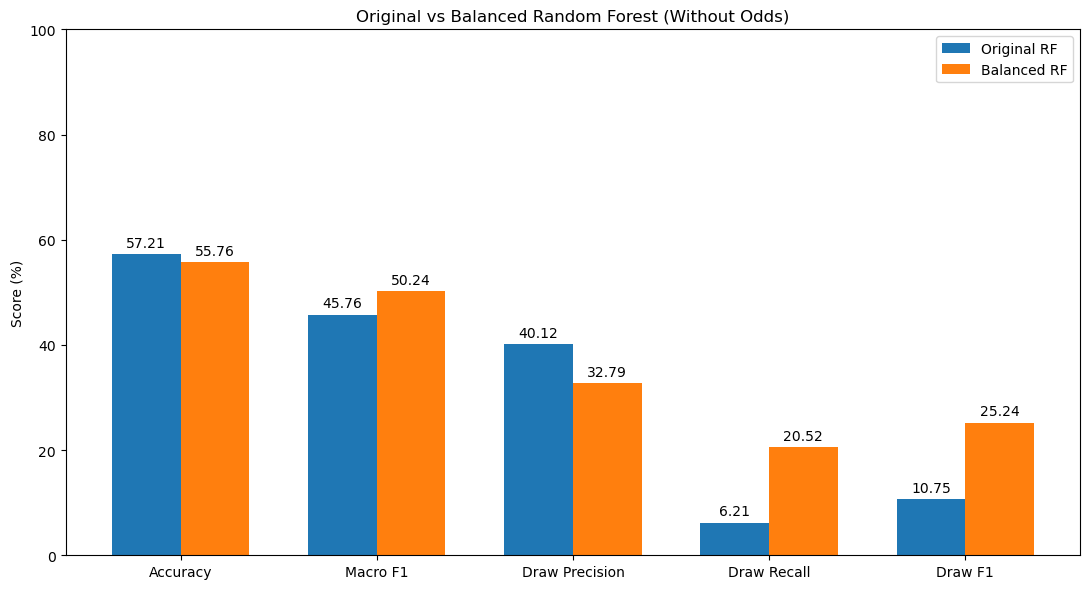

In [23]:

import numpy as np
import matplotlib.pyplot as plt

metrics = [
    "Accuracy", "Macro F1",
    "Draw Precision", "Draw Recall", "Draw F1"
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    baseline_balancing_comparison.loc["Original RF", metrics],
    width,
    label="Original RF"
)

bars2 = ax.bar(
    x + width / 2,
    baseline_balancing_comparison.loc["Balanced RF", metrics],
    width,
    label="Balanced RF"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_title("Original vs Balanced Random Forest (Without Odds)")
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()



### Class Weight Balancing Results

**Why we use class weighting**

We use `class_weight="balanced"` to investigate whether adjusting the importance of outcome categories during training can improve the classification of drawn matches.

**What our results mean**

After class weighting, Draw Recall increased from 6.21% to 20.52%, and Draw F1 increased from 10.75% to 25.24%.

Macro F1 also improved from 45.76% to 50.24%, indicating better average F1 performance across the three outcomes.

However, overall accuracy decreased from 57.21% to 55.76%, while Draw Precision decreased from 40.12% to 32.79%.

These results show that class weighting improved the model's ability to identify drawn matches, but also increased the proportion of incorrect draw predictions.

Therefore, the balanced model performed better according to Macro F1 and Draw Recall, while the original model performed better according to Accuracy and Draw Precision.
